Date - 23/11/2026
# EXPERIMENT 13 - Distributed File System and Loading Data into HDFS

### AIM: To simulate how HDFS splits a file into blocks, replicates them across DataNodes and recovers from a node failure.

QUESTION:
A smart-city project stores sensor logs in the Hadoop Distributed File System (HDFS). Write a Python simulation of a six-node, two-rack HDFS cluster with a NameNode and DataNodes. Load (put) a log file, inspect block placement, read it back, and show how HDFS keeps the file
available when a DataNode fails.

The program must:
1. Split the file into fixed-size blocks and assign a block ID to each.
2. Place three replicas of every block using rack-aware placement.
3. Maintain NameNode metadata (file to blocks, block to DataNodes) and a DataNode
storage report.
4. Read the file back and verify it with a checksum.
5. Simulate a DataNode failure, re-replicate the lost blocks and confirm the file is still
healthy.

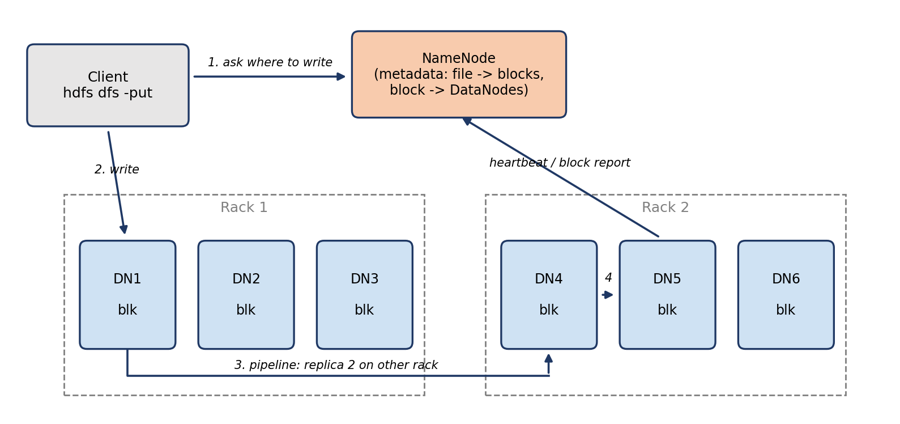

In [1]:

import hashlib
import itertools

BLOCK_SIZE = 64  # bytes (scaled down from HDFS default of 128 MB)
REPLICATION = 3


class DataNode:
    def __init__(self, name, rack):
        self.name, self.rack, self.alive = name, rack, True
        self.blocks = {}


class NameNode:
    """Keeps only metadata: file -> blocks, block -> DataNodes."""

    def __init__(self, datanodes):
        self.datanodes = datanodes
        self.namespace = {}  # path -> list of block ids
        self.block_map = {}  # block id -> list of DataNode names
        self._rr = itertools.cycle(range(len(datanodes)))
        self._next_id = 1

    def choose_targets(self):
        """Rack-aware: 1st replica on one rack, 2nd and 3rd on another rack."""
        live = [d for d in self.datanodes if d.alive]
        turn = next(self._rr)
        first = live[turn % len(live)]
        others = [d for d in live if d.rack != first.rack]
        second = others[turn % len(others)]
        third = [d for d in others if d.rack == second.rack and d is not second][
            0
        ]
        return [first, second, third]

    def put(self, path, data):
        ids = []
        for start in range(0, len(data), BLOCK_SIZE):
            chunk = data[start : start + BLOCK_SIZE]
            bid = f"blk_{self._next_id:04d}"
            self._next_id += 1
            targets = self.choose_targets()
            for dn in targets:  # replication pipeline
                dn.blocks[bid] = chunk
            self.block_map[bid] = [dn.name for dn in targets]
            ids.append(bid)
        self.namespace[path] = ids
        return ids

    def get(self, path):
        out = []
        for bid in self.namespace[path]:
            for name in self.block_map[bid]:
                dn = self.node(name)
                if dn.alive:  # read from first live replica
                    out.append(dn.blocks[bid])
                    break
        return "".join(out)

    def node(self, name):
        return next(d for d in self.datanodes if d.name == name)

    def handle_failure(self, name):
        failed = self.node(name)
        failed.alive = False
        repaired = 0
        for bid, holders in self.block_map.items():
            if name in holders:
                holders.remove(name)
                source = self.node(holders[0])
                spare = [
                    d for d in self.datanodes if d.alive and d.name not in holders
                ][0]
                spare.blocks[bid] = source.blocks[bid]
                holders.append(spare.name)
                repaired += 1
        return repaired


def checksum(text):
    return hashlib.md5(text.encode()).hexdigest()[:8]


cluster = [
    DataNode("DN1", "Rack-1"),
    DataNode("DN2", "Rack-1"),
    DataNode("DN3", "Rack-1"),
    DataNode("DN4", "Rack-2"),
    DataNode("DN5", "Rack-2"),
    DataNode("DN6", "Rack-2"),
]
nn = NameNode(cluster)

log = "\n".join(
    f"2026-03-0{d} 10:{m:02d} sensor={s} temp={30 + (d * m + s) % 9}"
    for d in range(1, 3)
    for m in (5, 20)
    for s in (1, 2)
)

print("Distributed File System Simulation (HDFS)")
print("=" * 45)
print(f"Block size = {BLOCK_SIZE} bytes | Replication factor = {REPLICATION}")
print("Cluster    :", ", ".join(f"{d.name}({d.rack})" for d in cluster))

print("\n$ hdfs dfs -put sensor_log.txt /data/sensor_log.txt")
blocks = nn.put("/data/sensor_log.txt", log)
print(f"File size  = {len(log)} bytes  ->  {len(blocks)} blocks")

print("\nNameNode metadata (block -> DataNodes):")
for bid in blocks:
    racks = {nn.node(n).rack for n in nn.block_map[bid]}
    print(f"  {bid}  {nn.block_map[bid]}  racks={sorted(racks)}")

print("\nDataNode storage report:")
for d in cluster:
    print(f"  {d.name}  blocks={sorted(d.blocks)}")

print("\n$ hdfs dfs -cat /data/sensor_log.txt | head -3")
data = nn.get("/data/sensor_log.txt")
print("\n".join(data.splitlines()[:3]))
print("Checksum original =", checksum(log), "| read back =", checksum(data))

print("\n*** DataNode DN1 fails (heartbeat lost) ***")
fixed = nn.handle_failure("DN1")
print("Under-replicated blocks re-replicated:", fixed)
for bid in blocks:
    print(f"  {bid}  {nn.block_map[bid]}")
data2 = nn.get("/data/sensor_log.txt")
print(
    "File readable after failure:", data2 == log, "| checksum =", checksum(data2)
)
print("\n$ hdfs fsck /data/sensor_log.txt -files -blocks")
healthy = all(len(v) == REPLICATION for v in nn.block_map.values())
print(
f"Total blocks: {len(blocks)} | Replication: {REPLICATION} | "
f"Status: {'HEALTHY' if healthy else 'CORRUPT'}"
)

Distributed File System Simulation (HDFS)
Block size = 64 bytes | Replication factor = 3
Cluster    : DN1(Rack-1), DN2(Rack-1), DN3(Rack-1), DN4(Rack-2), DN5(Rack-2), DN6(Rack-2)

$ hdfs dfs -put sensor_log.txt /data/sensor_log.txt
File size  = 271 bytes  ->  5 blocks

NameNode metadata (block -> DataNodes):
  blk_0001  ['DN1', 'DN4', 'DN5']  racks=['Rack-1', 'Rack-2']
  blk_0002  ['DN2', 'DN5', 'DN4']  racks=['Rack-1', 'Rack-2']
  blk_0003  ['DN3', 'DN6', 'DN4']  racks=['Rack-1', 'Rack-2']
  blk_0004  ['DN4', 'DN1', 'DN2']  racks=['Rack-1', 'Rack-2']
  blk_0005  ['DN5', 'DN2', 'DN1']  racks=['Rack-1', 'Rack-2']

DataNode storage report:
  DN1  blocks=['blk_0001', 'blk_0004', 'blk_0005']
  DN2  blocks=['blk_0002', 'blk_0004', 'blk_0005']
  DN3  blocks=['blk_0003']
  DN4  blocks=['blk_0001', 'blk_0002', 'blk_0003', 'blk_0004']
  DN5  blocks=['blk_0001', 'blk_0002', 'blk_0005']
  DN6  blocks=['blk_0003']

$ hdfs dfs -cat /data/sensor_log.txt | head -3
2026-03-01 10:05 sensor=1 temp=36
20

Date - 23/11/2026
# EXPERIMENT 14 - Word Count using MapReduce (Map, Shuffle-Sort and Reduce
Phases)

### AIM: To count word frequencies in news headlines using a Hadoop Streaming MapReduce program.
QUESTION:
A news agency wants to find the most frequent words in its headlines, which are stored as input
splits on three nodes. Write the mapper and reducer in Python in Hadoop Streaming style (read
stdin, write key<TAB>value). Show the output of the map phase, the combiner, shuffling and
sorting, and the reduce phase.

The program must:
1. Write a mapper that emits (word, 1) for every word in a line.
2. Write a reducer that sums the counts of sorted keys.
3. Use the reducer as a combiner on each mapper and show the reduction in pairs.
4. Show the grouped values after shuffling and sorting.
5. Display the final word counts, the number of distinct words and the top words.

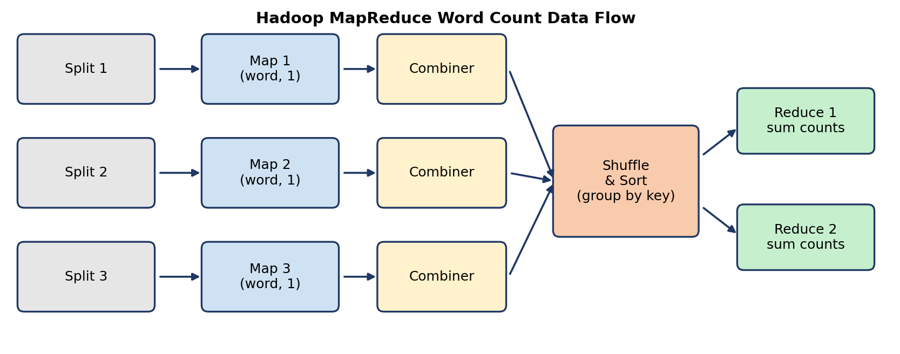

In [2]:
"""
Word count in Hadoop Streaming style.
  Local simulation : python exp14.py
  Hadoop Streaming : hadoop jar hadoop-streaming.jar \
                       -files exp14.py -mapper "python exp14.py map" \
                       -reducer "python exp14.py reduce" \
                       -input /data/news -output /out/wc
  Unix pipe test   : cat news.txt | python exp14.py map | sort | python exp14.py reduce
"""

import re
import sys
from itertools import groupby


def mapper(lines):
    for line in lines:
        for word in re.findall(r"[a-z]+", line.lower()):
            yield f"{word}\t1"


def reducer(lines):
    pairs = (line.rstrip("\n").split("\t") for line in lines)
    for word, group in groupby(pairs, key=lambda kv: kv[0]):
        yield f"{word}\t{sum(int(c) for _, c in group)}"


if len(sys.argv) > 1 and sys.argv[1] == "map":
    for out in mapper(sys.stdin):
        print(out)
    sys.exit()
if len(sys.argv) > 1 and sys.argv[1] == "reduce":
    for out in reducer(sys.stdin):
        print(out)
    sys.exit()

# ---------------- Local simulation of the Hadoop job ----------------
splits = {
    "split-1 (node1)": [
        "Data science uses data to create value",
        "Big data needs distributed storage",
    ],
    "split-2 (node2)": [
        "Hadoop stores big data in HDFS",
        "MapReduce processes data in parallel",
    ],
    "split-3 (node3)": [
        "Spark and Hadoop process big data",
        "Data drives science",
    ],
}

print("MapReduce Word Count on News Headlines")
print("=" * 42)

print("\n--- MAP PHASE ---")
mapped = {}
for split, lines in splits.items():
    out = list(mapper(lines))
    mapped[split] = out
    print(
        f"{split}: {len(out)} pairs ->",
        ", ".join(o.replace("\t", ":") for o in out[:6]),
        "...",
    )

print("\n--- COMBINER (local aggregation on each mapper) ---")
combined = []
for split, out in mapped.items():
    local = list(reducer(sorted(out)))
    combined.extend(local)
    print(f"{split}: {len(out)} pairs reduced to {len(local)}")

print("\n--- SHUFFLE AND SORT ---")
shuffled = sorted(combined)
for key, grp in groupby(shuffled, key=lambda s: s.split("\t")[0]):
    values = [g.split("\t")[1] for g in grp]
    if len(values) > 1:
        print(f"  {key:<12} -> {values}")
print("  (keys appearing on only one mapper are not shown)")

print("\n--- REDUCE PHASE ---")
result = [r.split("\t") for r in reducer(shuffled)]
result.sort(key=lambda kv: (-int(kv[1]), kv[0]))
print(f"{'WORD':<12}COUNT")
for word, count in result:
    print(f"{word:<12}{count}")

print("\nDistinct words :", len(result))
print("Total words    :", sum(int(c) for _, c in result))
print("Top 3 words    :", [w for w, _ in result[:3]])

MapReduce Word Count on News Headlines

--- MAP PHASE ---
split-1 (node1): 12 pairs -> data:1, science:1, uses:1, data:1, to:1, create:1 ...
split-2 (node2): 11 pairs -> hadoop:1, stores:1, big:1, data:1, in:1, hdfs:1 ...
split-3 (node3): 9 pairs -> spark:1, and:1, hadoop:1, process:1, big:1, data:1 ...

--- COMBINER (local aggregation on each mapper) ---
split-1 (node1): 12 pairs reduced to 10
split-2 (node2): 11 pairs reduced to 9
split-3 (node3): 9 pairs reduced to 8

--- SHUFFLE AND SORT ---
  big          -> ['1', '1', '1']
  data         -> ['2', '2', '3']
  hadoop       -> ['1', '1']
  science      -> ['1', '1']
  (keys appearing on only one mapper are not shown)

--- REDUCE PHASE ---
WORD        COUNT
data        7
big         3
hadoop      2
in          2
science     2
and         1
create      1
distributed 1
drives      1
hdfs        1
mapreduce   1
needs       1
parallel    1
process     1
processes   1
spark       1
storage     1
stores      1
to          1
uses        1
v

<>:4: SyntaxWarning: invalid escape sequence '\ '
<>:4: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_613/3188632061.py:4: SyntaxWarning: invalid escape sequence '\ '
  Hadoop Streaming : hadoop jar hadoop-streaming.jar \


Date - 24/11/2026
# EXPERIMENT 15 - Matrix-Vector Multiplication using MapReduce

### AIM: To compute the product of a sparse matrix and a vector using MapReduce, as used in one PageRank iteration.

QUESTION:
A search engine ranks five web pages using PageRank, which repeatedly multiplies the link
matrix M by the rank vector v. Because M is very large in practice, it is stored as (i, j, m_ij)
records and the product x = Mv is computed with MapReduce. Implement the mapper and
reducer and verify the result.

The program must:
1. Store the non-zero entries of M as (i, j, m_ij) records and v in a separate file.
2. Mapper: for each entry emit the key i with the value m_ij x v_j.
3. Shuffle and sort the values by row i.
4. Reducer: add the values for each i to obtain x_i.
5. Verify the result with NumPy and repeat the job to show PageRank converging.

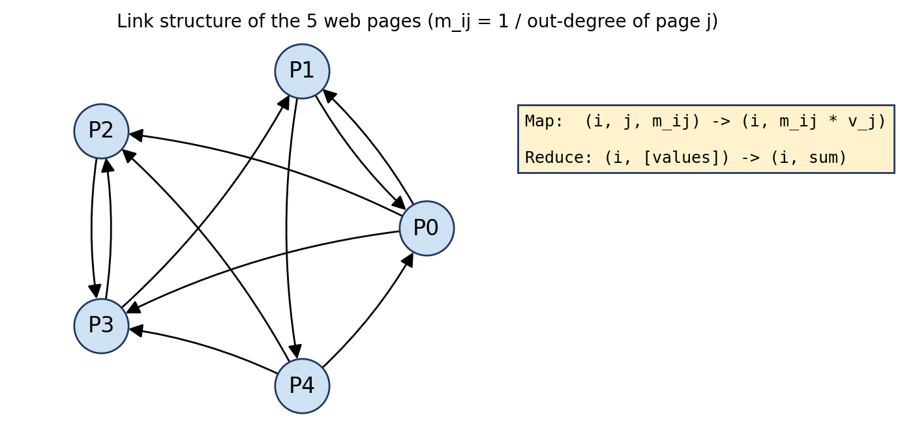

In [3]:
"""
Matrix-vector multiplication x = M.v with MapReduce (Hadoop Streaming style).
Input records : i<TAB>j<TAB>m_ij   (sparse matrix entries)
  Hadoop  : -mapper "python exp15.py map" -reducer "python exp15.py reduce"
            -files exp15.py,vector.txt
"""

import sys
from itertools import groupby
import numpy as np


def load_vector(path="vector.txt"):
    with open(path) as f:
        return {int(j): float(v) for j, v in (line.split() for line in f)}


def mapper(lines, v):
    for line in lines:
        i, j, m = line.split()
        yield f"{int(i)}\t{float(m) * v[int(j)]}"


def reducer(lines):
    pairs = (l.rstrip("\n").split("\t") for l in lines)
    for i, grp in groupby(pairs, key=lambda kv: int(kv[0])):
        yield f"{i}\t{sum(float(x) for _, x in grp)}"


if len(sys.argv) > 1 and sys.argv[1] in ("map", "reduce"):
    if sys.argv[1] == "map":
        out = mapper(sys.stdin, load_vector())
    else:
        out = reducer(sys.stdin)
    for o in out:
        print(o)
    sys.exit()

# ---------------- Local simulation ----------------
# Link matrix of a 5-page website
# (column j = page j shares its rank equally among the pages it links to)
M = np.array(
    [
        [0, 0.5, 0, 0, 1 / 3],
        [1 / 3, 0, 0, 0.5, 0],
        [1 / 3, 0, 0, 0.5, 1 / 3],
        [1 / 3, 0, 1.0, 0, 1 / 3],
        [0, 0.5, 0, 0, 0],
    ]
)
v = np.array([0.2, 0.2, 0.2, 0.2, 0.2])  # current PageRank estimate

entries = [
    f"{i}\t{j}\t{M[i, j]}" for i in range(5) for j in range(5) if M[i, j] != 0
]
with open("matrix.txt", "w") as f:
    f.write("\n".join(entries))
with open("vector.txt", "w") as f:
    f.write("\n".join(f"{j} {val}" for j, val in enumerate(v)))
vec = load_vector()

print("Matrix-Vector Multiplication using MapReduce (PageRank step)")
print("=" * 60)
print("Matrix M (5 x 5):")
print(np.round(M, 3))
print("Vector v:", v)
print(f"Non-zero entries stored as (i, j, m_ij): {len(entries)} of {M.size}")

splits = [entries[:5], entries[5:]]
print("\n--- MAP PHASE: emit (i, m_ij * v_j) ---")
mapped = []
for s, chunk in enumerate(splits, 1):
    out = list(mapper(chunk, vec))
    mapped += out
    print(f"Mapper {s}:")
    for rec, o in zip(chunk, out):
        i, j, m = rec.split("\t")
        print(
            f"  ({i},{j}, {float(m):.3f}) -> key {o.split()[0]}, "
            f"value {float(o.split()[1]):.4f}"
        )

print("\n--- SHUFFLE AND SORT: group values by row i ---")
shuffled = sorted(mapped, key=lambda s: int(s.split("\t")[0]))
for i, grp in groupby(shuffled, key=lambda s: s.split("\t")[0]):
    print(f"  row {i}: {[round(float(g.split()[1]), 4) for g in grp]}")

print("\n--- REDUCE PHASE: x_i = sum of values ---")
x = np.zeros(5)
for r in reducer(shuffled):
    i, val = r.split("\t")
    x[int(i)] = float(val)
    print(f"  x[{i}] = {float(val):.4f}")

print("\nMapReduce result x  :", np.round(x, 4))
print("NumPy check   M @ v :", np.round(M @ v, 4))
print("Results match       :", np.allclose(x, M @ v))

print("\nRepeating the job (power iteration) gives PageRank:")
r = v.copy()
for it in range(1, 31):
    r_new = M @ r
    if it in (1, 2, 5, 30):
        print(f"  iteration {it:>2}: {np.round(r_new, 4)}")
    r = r_new
print("Most important page:", int(np.argmax(r)))

Matrix-Vector Multiplication using MapReduce (PageRank step)
Matrix M (5 x 5):
[[0.    0.5   0.    0.    0.333]
 [0.333 0.    0.    0.5   0.   ]
 [0.333 0.    0.    0.5   0.333]
 [0.333 0.    1.    0.    0.333]
 [0.    0.5   0.    0.    0.   ]]
Vector v: [0.2 0.2 0.2 0.2 0.2]
Non-zero entries stored as (i, j, m_ij): 11 of 25

--- MAP PHASE: emit (i, m_ij * v_j) ---
Mapper 1:
  (0,1, 0.500) -> key 0, value 0.1000
  (0,4, 0.333) -> key 0, value 0.0667
  (1,0, 0.333) -> key 1, value 0.0667
  (1,3, 0.500) -> key 1, value 0.1000
  (2,0, 0.333) -> key 2, value 0.0667
Mapper 2:
  (2,3, 0.500) -> key 2, value 0.1000
  (2,4, 0.333) -> key 2, value 0.0667
  (3,0, 0.333) -> key 3, value 0.0667
  (3,2, 1.000) -> key 3, value 0.2000
  (3,4, 0.333) -> key 3, value 0.0667
  (4,1, 0.500) -> key 4, value 0.1000

--- SHUFFLE AND SORT: group values by row i ---
  row 0: [0.1, 0.0667]
  row 1: [0.0667, 0.1]
  row 2: [0.0667, 0.1, 0.0667]
  row 3: [0.0667, 0.2, 0.0667]
  row 4: [0.1]

--- REDUCE PHASE: x_i

Date - 24/11/2026
# EXPERIMENT 16 - Relational Join and Aggregation using MapReduce

### AIM: To join customer and order data and compute city-wise sales using chained MapReduce jobs.

QUESTION:
An online store keeps CUSTOMERS(cust_id, name, city) and ORDERS(order_id, cust_id,
amount) as separate files in HDFS. Management wants the total revenue, number of orders,
maximum order and average order value for each city. Implement this as two chained
MapReduce jobs: a reduce-side join followed by grouping and aggregation.

The program must:
1. Job 1 mapper: emit cust_id as the key and a record tagged with its source relation.
2. Job 1 reducer: combine customer and order records with the same key (inner join).
3. Job 2 mapper: emit (city, amount) from each joined record.
4. Job 2 reducer: compute total, count, maximum and average per city.
5. Show the output of every phase and explain why an order without a matching
customer is dropped.

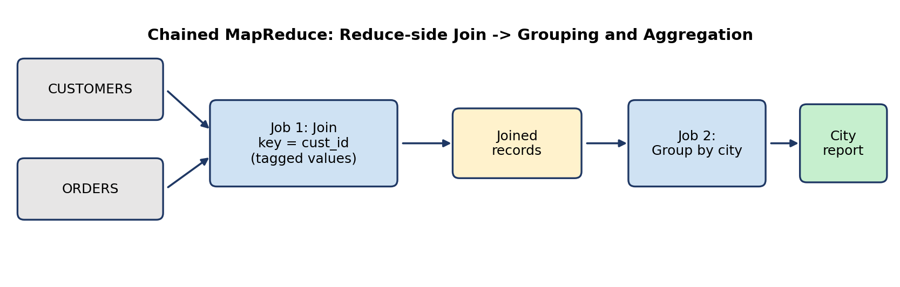

In [4]:
"""
Two chained MapReduce jobs (Hadoop Streaming style):
  Job 1 - reduce-side natural join of CUSTOMERS(cust_id, name, city)
          and ORDERS(order_id, cust_id, amount)
  Job 2 - grouping and aggregation: revenue, order count and maximum order per city
"""

from itertools import groupby

customers = [
    "C1,Kavya,Chennai",
    "C2,Ravi,Bengaluru",
    "C3,Sana,Chennai",
    "C4,Tarun,Hyderabad",
    "C5,Uma,Bengaluru",
]
orders = [
    "O1,C1,2500",
    "O2,C2,1800",
    "O3,C1,700",
    "O4,C3,4200",
    "O5,C4,1500",
    "O6,C2,3100",
    "O7,C5,950",
    "O8,C3,600",
    "O9,C9,800",
]


# ---------------- Job 1: Join ----------------
def join_mapper(source, line):
    f = line.split(",")
    if source == "customers":  # tag each record with its relation
        return f[0], ("C", f[1], f[2])
    return f[1], ("O", f[0], int(f[2]))


def join_reducer(cust_id, values):
    cust = [v for v in values if v[0] == "C"]
    ords = [v for v in values if v[0] == "O"]
    for c in cust:  # inner join: needs both sides
        for o in ords:
            yield cust_id, c[1], c[2], o[1], o[2]


# ---------------- Job 2: Group by city ----------------
def agg_mapper(joined_row):
    _, _, city, _, amount = joined_row
    return city, amount


def agg_reducer(city, amounts):
    return city, sum(amounts), len(amounts), max(amounts)


def shuffle(pairs):
    pairs = sorted(pairs, key=lambda kv: kv[0])
    return [
        (k, [v for _, v in g]) for k, g in groupby(pairs, key=lambda kv: kv[0])
    ]


print("Sales Analytics: Join and Aggregation using MapReduce")
print("=" * 55)

print("\nJOB 1 - MAP (key = cust_id, value tagged with relation):")
mapped = [join_mapper("customers", l) for l in customers] + [
    join_mapper("orders", l) for l in orders
]
for k, v in mapped:
    print(f"  {k} -> {v}")

print("\nJOB 1 - SHUFFLE AND SORT:")
groups = shuffle(mapped)
for k, vals in groups:
    print(f"  {k}: {vals}")

print("\nJOB 1 - REDUCE (joined records):")
joined = [row for k, vals in groups for row in join_reducer(k, vals)]
print(f"  {'cust':<5}{'name':<7}{'city':<11}{'order':<7}amount")
for row in joined:
    print(f"  {row[0]:<5}{row[1]:<7}{row[2]:<11}{row[3]:<7}{row[4]}")
print("  Note: order O9 (cust C9) has no matching customer and is dropped.")

print("\nJOB 2 - MAP (key = city, value = amount):")
mapped2 = [agg_mapper(r) for r in joined]
print(" ", mapped2)

print("\nJOB 2 - SHUFFLE AND SORT:")
groups2 = shuffle(mapped2)
for city, vals in groups2:
    print(f"  {city}: {vals}")

print("\nJOB 2 - REDUCE (aggregates per city):")
print(f"  {'City':<11}{'Revenue':>8}{'Orders':>8}{'Max':>7}{'Avg':>9}")
results = [agg_reducer(c, v) for c, v in groups2]
for city, total, cnt, mx in sorted(results, key=lambda r: -r[1]):
    print(f"  {city:<11}{total:>8}{cnt:>8}{mx:>7}{total / cnt:>9.2f}")
print("\nGrand total revenue:", sum(r[1] for r in results))

Sales Analytics: Join and Aggregation using MapReduce

JOB 1 - MAP (key = cust_id, value tagged with relation):
  C1 -> ('C', 'Kavya', 'Chennai')
  C2 -> ('C', 'Ravi', 'Bengaluru')
  C3 -> ('C', 'Sana', 'Chennai')
  C4 -> ('C', 'Tarun', 'Hyderabad')
  C5 -> ('C', 'Uma', 'Bengaluru')
  C1 -> ('O', 'O1', 2500)
  C2 -> ('O', 'O2', 1800)
  C1 -> ('O', 'O3', 700)
  C3 -> ('O', 'O4', 4200)
  C4 -> ('O', 'O5', 1500)
  C2 -> ('O', 'O6', 3100)
  C5 -> ('O', 'O7', 950)
  C3 -> ('O', 'O8', 600)
  C9 -> ('O', 'O9', 800)

JOB 1 - SHUFFLE AND SORT:
  C1: [('C', 'Kavya', 'Chennai'), ('O', 'O1', 2500), ('O', 'O3', 700)]
  C2: [('C', 'Ravi', 'Bengaluru'), ('O', 'O2', 1800), ('O', 'O6', 3100)]
  C3: [('C', 'Sana', 'Chennai'), ('O', 'O4', 4200), ('O', 'O8', 600)]
  C4: [('C', 'Tarun', 'Hyderabad'), ('O', 'O5', 1500)]
  C5: [('C', 'Uma', 'Bengaluru'), ('O', 'O7', 950)]
  C9: [('O', 'O9', 800)]

JOB 1 - REDUCE (joined records):
  cust name   city       order  amount
  C1   Kavya  Chennai    O1     2500
  C